# TCN Adding Problem: Colab reproduction

Run code cells in order on a CUDA GPU runtime. This notebook contains saved results from a single L4 run per configuration on 2026-11-10. Re-execution replaces outputs; numerical agreement is not guaranteed.

Upstream: https://github.com/locuslab/TCN (MIT), commit `2f8c2b817050206397458dfd1f5a25ce8a32fe65`.

Publication edits: pin upstream checkout; carry generated log paths into backup/plot cells; raise on training-process failure; remove transient download UI outputs. Training settings and saved experimental metrics are unchanged. The publication edits have not been rerun on Colab. Archived logs are in this repository's `logs/` folder. No trained checkpoints are included.


In [ ]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU가 연결되지 않았습니다. 런타임 설정을 확인하세요.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA 사용 가능: True
GPU: NVIDIA L4


In [ ]:
from pathlib import Path
import subprocess
import os
import sys

repo_dir = Path("/content/TCN")
commit = "2f8c2b817050206397458dfd1f5a25ce8a32fe65"
if not repo_dir.exists():
    subprocess.run(["git", "clone", "https://github.com/locuslab/TCN.git", str(repo_dir)], check=True)
subprocess.run(["git", "checkout", "--detach", commit], cwd=repo_dir, check=True)
os.chdir(repo_dir)
if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))
print("Working directory:", Path.cwd())
subprocess.run(["git", "rev-parse", "HEAD"], check=True)


In [ ]:
import torch
from TCN.adding_problem.model import TCN

# 원본 Adding Problem 기본 구조
model = TCN(
    input_size=2,
    output_size=1,
    num_channels=[30] * 8,
    kernel_size=7,
    dropout=0.0,
).to("cuda")

# 샘플 4개, 각 시점의 값 2개, 시퀀스 길이 400
x = torch.randn(4, 2, 400, device="cuda")

model.eval()
with torch.no_grad():
    y = model(x)

print("입력 모양:", tuple(x.shape))
print("출력 모양:", tuple(y.shape))
print("모델 위치:", next(model.parameters()).device)
print("출력 위치:", y.device)
print("출력에 NaN·무한대 없음:", torch.isfinite(y).all().item())

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


입력 모양: (4, 2, 400)
출력 모양: (4, 1)
모델 위치: cuda:0
출력 위치: cuda:0
출력에 NaN·무한대 없음: True


In [ ]:
import subprocess
import sys
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(exist_ok=True)
log_path = log_dir / f"adding_T200_{datetime.now():%Y%m%d_%H%M%S}.log"

# 원본은 NumPy 시드를 설정하지 않으므로 실행 전에 추가
runner = """
import numpy as np
import runpy
import sys

np.random.seed(1111)
sys.argv = [
    "add_test",
    "--seq_len", "200",
    "--levels", "7",
    "--epochs", "3",
    "--seed", "1111",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("로그 저장 위치:", log_path)

with log_path.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

    return_code = process.wait()

print("\n종료 코드:", return_code)
print("로그 파일:", log_path)
t200_log_path = log_path
if return_code != 0:
    raise RuntimeError(f"Training failed; inspect {log_path}")


로그 저장 위치: /content/TCN/reproduction_logs/adding_T200_20261110_075016.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=3, ksize=7, levels=7, seq_len=200, log_interval=100, lr=0.004, optim='Adam', nhid=30, seed=1111)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.240956
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.164279
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.171493
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.170041
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.169417
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.169233
Train Epoch:  1 [ 22368/ 50000 (45%)]	Learning rate: 0.0040	Loss: 0.

In [ ]:
import subprocess
import sys
import time
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(exist_ok=True)
log_path = log_dir / f"adding_T400_{datetime.now():%Y%m%d_%H%M%S}.log"

runner = """
import numpy as np
import runpy
import sys

np.random.seed(1111)
sys.argv = [
    "add_test",
    "--seq_len", "400",
    "--levels", "8",
    "--epochs", "3",
    "--seed", "1111",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("로그 저장 위치:", log_path)
started = time.perf_counter()

with log_path.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

    return_code = process.wait()
    elapsed = time.perf_counter() - started

    summary = (
        f"\n종료 코드: {return_code}\n"
        f"전체 실행 시간: {elapsed:.1f}초\n"
    )
    print(summary)
    log_file.write(summary)

print("로그 파일:", log_path)
t400_log_path = log_path
if return_code != 0:
    raise RuntimeError(f"Training failed; inspect {log_path}")


로그 저장 위치: /content/TCN/reproduction_logs/adding_T400_20261110_075714.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=3, ksize=7, levels=8, seq_len=400, log_interval=100, lr=0.004, optim='Adam', nhid=30, seed=1111)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.339744
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.166161
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.165545
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.173474
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.169182
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.168962
Train Epoch:  1 [ 22368/ 50000 (45%)]	Learning rate: 0.0040	Loss: 0.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

log_paths = [t200_log_path, t400_log_path]
for path in log_paths:
    if not path.is_file():
        raise FileNotFoundError(path)
    print(f"Confirmed: {path.name} ({path.stat().st_size:,} bytes)")
zip_path = Path("/content/TCN_Adding_Problem_logs.zip")
with ZipFile(zip_path, "w") as archive:
    for path in log_paths:
        archive.write(path, arcname=path.name)
files.download(str(zip_path))


T=200, 7 blocks → Test MSE: [0.001812, 0.000285, 0.000531]
T=400, 8 blocks → Test MSE: [0.166145, 0.001375, 0.002161]


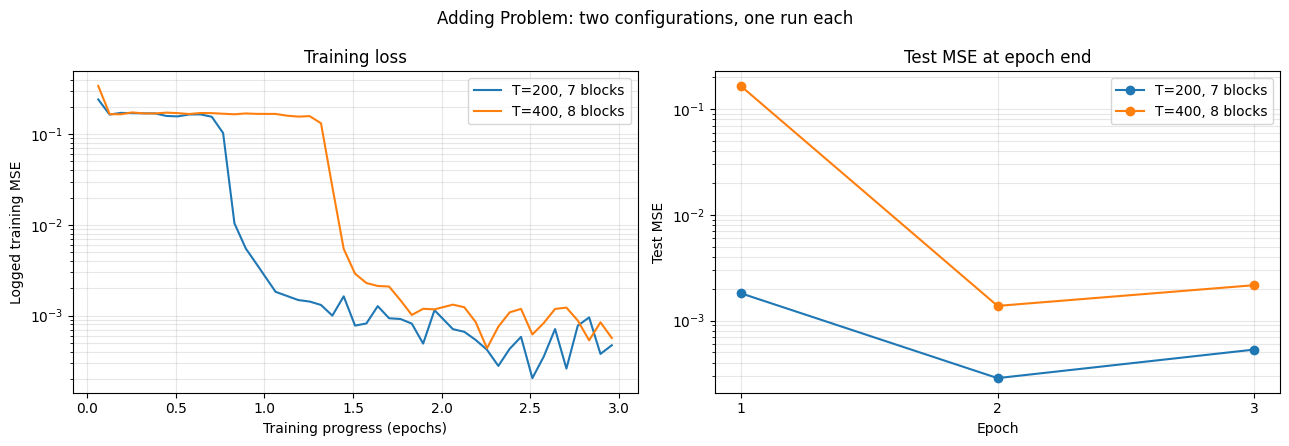

그래프 저장 위치: /content/TCN/reproduction_logs/adding_T200_T400_comparison.png


In [ ]:
import re
from pathlib import Path
import matplotlib.pyplot as plt

log_dir = Path("/content/TCN/reproduction_logs")
experiments = {
    "T=200, 7 blocks": t200_log_path,
    "T=400, 8 blocks": t400_log_path,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for label, path in experiments.items():
    text = path.read_text()

    # 학습 로그에서 에폭, 처리한 샘플 수, 손실 추출
    records = re.findall(
        r"Train Epoch:\s*(\d+)\s*\[\s*(\d+)/\s*(\d+)"
        r"\s*\(\d+%\)\].*?Loss:\s*([0-9.eE+-]+)",
        text,
    )

    # 예: 1에폭의 50% → 가로축 0.5
    progress = [
        int(epoch) - 1 + int(done) / int(total)
        for epoch, done, total, loss in records
    ]
    train_loss = [float(loss) for _, _, _, loss in records]

    test_mse = [
        float(value)
        for value in re.findall(
            r"Test set: Average loss:\s*([0-9.eE+-]+)", text
        )
    ]

    if not records or len(test_mse) != 3:
        raise ValueError(f"로그 내용을 확인하세요: {path.name}")

    axes[0].plot(progress, train_loss, label=label)
    axes[1].plot([1, 2, 3], test_mse, marker="o", label=label)

    print(label, "→ Test MSE:", test_mse)

axes[0].set_title("Training loss")
axes[0].set_xlabel("Training progress (epochs)")
axes[0].set_ylabel("Logged training MSE")

axes[1].set_title("Test MSE at epoch end")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test MSE")
axes[1].set_xticks([1, 2, 3])

for ax in axes:
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

fig.suptitle("Adding Problem: two configurations, one run each")
fig.tight_layout()

figure_path = log_dir / "adding_T200_T400_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 위치:", figure_path)

In [1]:
from google.colab import files

files.download(
    "/content/TCN/reproduction_logs/adding_T200_T400_comparison.png"
)

FileNotFoundError: Cannot find file: /content/TCN/reproduction_logs/adding_T200_T400_comparison.png

In [3]:
!git clone https://github.com/locuslab/TCN.git /content/TCN
!git -C /content/TCN checkout 2f8c2b817050206397458dfd1f5a25ce8a32fe65
!git -C /content/TCN rev-parse HEAD

Cloning into '/content/TCN'...
remote: Enumerating objects: 150, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 150 (delta 0), reused 4 (delta 0), pack-reused 143 (from 1)
Receiving objects: 100% (150/150), 16.84 MiB | 24.99 MiB/s, done.
Resolving deltas: 100% (61/61), done.
Note: switching to '2f8c2b817050206397458dfd1f5a25ce8a32fe65'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 2f8c2b8 Added old LAMBADA data; updated note
2f8c2b81705020639745

In [4]:
import torch

print("CUDA 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA 사용 가능: True
GPU: Tesla T4


In [5]:
import sys
sys.path.insert(0, "/content/TCN")

import torch
from TCN.adding_problem.model import TCN

model = TCN(
    input_size=2,
    output_size=1,
    num_channels=[27] * 7,
    kernel_size=6,
    dropout=0,
).cuda()

sample = torch.rand(4, 2, 200, device="cuda")
output = model(sample)

print("입력 모양:", tuple(sample.shape))
print("출력 모양:", tuple(output.shape))
print("출력 위치:", output.device)
print("출력에 NaN·무한대 없음:", torch.isfinite(output).all().item())

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


입력 모양: (4, 2, 200)
출력 모양: (4, 1)
출력 위치: cuda:0
출력에 NaN·무한대 없음: True


In [6]:
import subprocess
import sys
import time
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(parents=True, exist_ok=True)
log_path = log_dir / f"adding_paper_T600_k8_l8_h24_{datetime.now():%Y%m%d_%H%M%S}.log"

runner = """
import numpy as np
import runpy
import sys

np.random.seed(1111)
sys.argv = [
    "add_test",
    "--seq_len", "600",
    "--ksize", "8",
    "--levels", "8",
    "--nhid", "24",
    "--epochs", "3",
    "--seed", "1111",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("설정: T=600, 커널 8, 블록 8, 채널 24 / 3에폭")
print("로그 저장 위치:", log_path)
started = time.perf_counter()

with log_path.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

return_code = process.wait()
print("\n종료 코드:", return_code)
print(f"전체 실행 시간: {time.perf_counter() - started:.1f}초")
print("로그 파일:", log_path)
if return_code != 0:
    raise RuntimeError("실험 실행에 실패했습니다. 위 로그를 확인해 주세요.")

설정: T=600, 커널 8, 블록 8, 채널 24 / 3에폭
로그 저장 위치: /content/TCN/reproduction_logs/adding_paper_T600_k8_l8_h24_20261124_025657.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=3, ksize=8, levels=8, seq_len=600, log_interval=100, lr=0.004, optim='Adam', nhid=24, seed=1111)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.382370
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.175314
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.182030
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.171048
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.180519
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.169867
Train Epoch:  1 [

In [7]:
from google.colab import files

files.download(
    "/content/TCN/reproduction_logs/"
    "adding_paper_T600_k8_l8_h24_20261124_025657.log"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from TCN.adding_problem.utils import data_generator

X, Y = data_generator(4, 600)

print("입력 X:", tuple(X.shape))
print("정답 Y:", tuple(Y.shape))
print("첫 번째 정답:", Y[0].item())

입력 X: (4, 2, 600)
정답 Y: (4, 1)
첫 번째 정답: 1.8495622873306274


In [9]:
import torch
from torch import nn

class AddingGRU(nn.Module):
    def __init__(self, hidden_size=150):
        super().__init__()
        self.gru = nn.GRU(
            input_size=2,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # 원본 데이터: (샘플, 채널, 길이)
        # GRU 입력:   (샘플, 길이, 채널)
        x = x.transpose(1, 2)
        _, last_hidden = self.gru(x)
        return self.output(last_hidden[-1])

gru_model = AddingGRU().cuda()
with torch.no_grad():
    prediction = gru_model(X.cuda())

print("예측값 모양:", tuple(prediction.shape))
print("모델 파라미터 수:", sum(p.numel() for p in gru_model.parameters()))
print("예측값에 NaN·무한대 없음:", torch.isfinite(prediction).all().item())

예측값 모양: (4, 1)
모델 파라미터 수: 69451
예측값에 NaN·무한대 없음: True


In [10]:
import time
import numpy as np
import torch
import torch.nn.functional as F
from TCN.adding_problem.utils import data_generator

# TCN 실행과 같은 시드 및 데이터 생성 순서
np.random.seed(1111)
torch.manual_seed(1111)

gru600_X_train, gru600_Y_train = data_generator(50000, 600)
gru600_X_test, gru600_Y_test = data_generator(1000, 600)

gru600_X_train = gru600_X_train.cuda()
gru600_Y_train = gru600_Y_train.cuda()
gru600_X_test = gru600_X_test.cuda()
gru600_Y_test = gru600_Y_test.cuda()

gru600_model = AddingGRU(hidden_size=150).cuda()
gru600_optimizer = torch.optim.Adam(gru600_model.parameters(), lr=0.004)

print("학습 데이터:", tuple(gru600_X_train.shape))
print("테스트 데이터:", tuple(gru600_X_test.shape))
print("GRU 파라미터:", sum(p.numel() for p in gru600_model.parameters()))

started = time.perf_counter()
gru600_model.train()

for start in range(0, len(gru600_X_train), 32):
    end = min(start + 32, len(gru600_X_train))
    x = gru600_X_train[start:end]
    y = gru600_Y_train[start:end]

    gru600_optimizer.zero_grad()
    prediction = gru600_model(x)
    loss = F.mse_loss(prediction, y)
    loss.backward()
    gru600_optimizer.step()

    if end % 6400 == 0 or end == len(gru600_X_train):
        print(f"학습 진행: {end}/50000, 마지막 배치 MSE: {loss.item():.6f}", flush=True)

gru600_model.eval()
with torch.no_grad():
    gru600_test_mse = F.mse_loss(
        gru600_model(gru600_X_test), gru600_Y_test
    ).item()

torch.cuda.synchronize()
print(f"1에폭 테스트 MSE: {gru600_test_mse:.6f}")
print(f"1에폭 실행 시간: {time.perf_counter() - started:.1f}초")

학습 데이터: (50000, 2, 600)
테스트 데이터: (1000, 2, 600)
GRU 파라미터: 69451
학습 진행: 6400/50000, 마지막 배치 MSE: 0.205358
학습 진행: 12800/50000, 마지막 배치 MSE: 0.197677
학습 진행: 19200/50000, 마지막 배치 MSE: 0.186459
학습 진행: 25600/50000, 마지막 배치 MSE: 0.124370
학습 진행: 32000/50000, 마지막 배치 MSE: 0.004141
학습 진행: 38400/50000, 마지막 배치 MSE: 0.000592
학습 진행: 44800/50000, 마지막 배치 MSE: 0.000767
학습 진행: 50000/50000, 마지막 배치 MSE: 0.000741
1에폭 테스트 MSE: 0.000365
1에폭 실행 시간: 24.1초


In [11]:
import time
import torch.nn.functional as F

gru600_results = [(1, gru600_test_mse)]
started = time.perf_counter()

for epoch in (2, 3):
    gru600_model.train()

    for start in range(0, len(gru600_X_train), 32):
        end = min(start + 32, len(gru600_X_train))
        x = gru600_X_train[start:end]
        y = gru600_Y_train[start:end]

        gru600_optimizer.zero_grad()
        prediction = gru600_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        gru600_optimizer.step()

        if end % 12800 == 0 or end == len(gru600_X_train):
            print(
                f"{epoch}에폭 진행: {end}/50000, "
                f"마지막 배치 MSE: {loss.item():.6f}",
                flush=True,
            )

    gru600_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            gru600_model(gru600_X_test), gru600_Y_test
        ).item()

    gru600_results.append((epoch, test_mse))
    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

torch.cuda.synchronize()
print("\nGRU T=600 결과:", gru600_results)
print(f"추가 2에폭 실행 시간: {time.perf_counter() - started:.1f}초")

2에폭 진행: 12800/50000, 마지막 배치 MSE: 0.000646
2에폭 진행: 25600/50000, 마지막 배치 MSE: 0.000117
2에폭 진행: 38400/50000, 마지막 배치 MSE: 0.000062
2에폭 진행: 50000/50000, 마지막 배치 MSE: 0.000101
2에폭 테스트 MSE: 0.000203
3에폭 진행: 12800/50000, 마지막 배치 MSE: 0.000118
3에폭 진행: 25600/50000, 마지막 배치 MSE: 0.000021
3에폭 진행: 38400/50000, 마지막 배치 MSE: 0.000018
3에폭 진행: 50000/50000, 마지막 배치 MSE: 0.000122
3에폭 테스트 MSE: 0.000115

GRU T=600 결과: [(1, 0.0003653762396425009), (2, 0.00020326652156654745), (3, 0.0001147756920545362)]
추가 2에폭 실행 시간: 48.8초


In [12]:
import json
import torch
import zipfile
from pathlib import Path
from google.colab import files

save_dir = Path("/content/TCN/reproduction_logs")
save_dir.mkdir(parents=True, exist_ok=True)

results_path = save_dir / "adding_gru_T600_results_20261124.json"
checkpoint_path = save_dir / "adding_gru_T600_checkpoint_20261124.pt"
zip_path = save_dir / "adding_gru_T600_backup_20261124.zip"

results = {
    "task": "Adding Problem",
    "model": "single-layer PyTorch GRU with linear output",
    "sequence_length": 600,
    "hidden_size": 150,
    "parameter_count": 69451,
    "train_samples": 50000,
    "test_samples": 1000,
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate": 0.004,
    "numpy_seed": 1111,
    "torch_seed": 1111,
    "test_mse_by_epoch": [
        {"epoch": epoch, "test_mse": mse}
        for epoch, mse in gru600_results
    ],
}

results_path.write_text(
    json.dumps(results, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

torch.save(
    {
        "model_state_dict": gru600_model.state_dict(),
        "optimizer_state_dict": gru600_optimizer.state_dict(),
        "completed_epochs": 3,
    },
    checkpoint_path,
)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    archive.write(results_path, results_path.name)
    archive.write(checkpoint_path, checkpoint_path.name)

print("백업 파일:", zip_path)
files.download(str(zip_path))

백업 파일: /content/TCN/reproduction_logs/adding_gru_T600_backup_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import time
import torch
import torch.nn.functional as F
from torch import nn

class AddingLSTM(nn.Module):
    def __init__(self, hidden_size=130):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=2,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = x.transpose(1, 2)  # (샘플, 길이, 채널)
        _, (last_hidden, _) = self.lstm(x)
        return self.output(last_hidden[-1])

torch.manual_seed(1111)
lstm600_model = AddingLSTM(hidden_size=130).cuda()
lstm600_optimizer = torch.optim.Adam(lstm600_model.parameters(), lr=0.004)
lstm600_results = []

print("LSTM 파라미터:", sum(p.numel() for p in lstm600_model.parameters()))
started = time.perf_counter()

for epoch in (1, 2, 3):
    lstm600_model.train()

    for start in range(0, len(gru600_X_train), 32):
        end = min(start + 32, len(gru600_X_train))
        x = gru600_X_train[start:end]
        y = gru600_Y_train[start:end]

        lstm600_optimizer.zero_grad()
        prediction = lstm600_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        lstm600_optimizer.step()

        if end % 12800 == 0 or end == len(gru600_X_train):
            print(
                f"{epoch}에폭 진행: {end}/50000, "
                f"마지막 배치 MSE: {loss.item():.6f}",
                flush=True,
            )

    lstm600_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            lstm600_model(gru600_X_test), gru600_Y_test
        ).item()

    lstm600_results.append((epoch, test_mse))
    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

torch.cuda.synchronize()
print("\nLSTM T=600 결과:", lstm600_results)
print(f"전체 실행 시간: {time.perf_counter() - started:.1f}초")

LSTM 파라미터: 69811
1에폭 진행: 12800/50000, 마지막 배치 MSE: 0.197890
1에폭 진행: 25600/50000, 마지막 배치 MSE: 0.124368
1에폭 진행: 38400/50000, 마지막 배치 MSE: 0.151938
1에폭 진행: 50000/50000, 마지막 배치 MSE: 0.185337
1에폭 테스트 MSE: 0.181795
2에폭 진행: 12800/50000, 마지막 배치 MSE: 0.197887
2에폭 진행: 25600/50000, 마지막 배치 MSE: 0.121447
2에폭 진행: 38400/50000, 마지막 배치 MSE: 0.150521
2에폭 진행: 50000/50000, 마지막 배치 MSE: 0.184799
2에폭 테스트 MSE: 0.181915
3에폭 진행: 12800/50000, 마지막 배치 MSE: 0.195535
3에폭 진행: 25600/50000, 마지막 배치 MSE: 0.120834
3에폭 진행: 38400/50000, 마지막 배치 MSE: 0.145610
3에폭 진행: 50000/50000, 마지막 배치 MSE: 0.184822
3에폭 테스트 MSE: 0.181890

LSTM T=600 결과: [(1, 0.18179546296596527), (2, 0.18191483616828918), (3, 0.1818898618221283)]
전체 실행 시간: 143.7초


In [14]:
import json
import zipfile
from pathlib import Path
from google.colab import files

lstm600_model.eval()
with torch.no_grad():
    lstm_predictions = lstm600_model(gru600_X_test)
    constant_one_mse = F.mse_loss(
        torch.ones_like(gru600_Y_test), gru600_Y_test
    ).item()

print("정답 평균:", gru600_Y_test.mean().item())
print("정답 표준편차:", gru600_Y_test.std().item())
print("예측 평균:", lstm_predictions.mean().item())
print("예측 표준편차:", lstm_predictions.std().item())
print("항상 1을 예측할 때의 테스트 MSE:", constant_one_mse)
print("LSTM 3에폭 테스트 MSE:", lstm600_results[-1][1])

save_dir = Path("/content/TCN/reproduction_logs")
save_dir.mkdir(parents=True, exist_ok=True)

results_path = save_dir / "adding_lstm_T600_results_20261124.json"
checkpoint_path = save_dir / "adding_lstm_T600_checkpoint_20261124.pt"
zip_path = save_dir / "adding_lstm_T600_backup_20261124.zip"

results = {
    "task": "Adding Problem",
    "model": "single-layer PyTorch LSTM with linear output",
    "sequence_length": 600,
    "hidden_size": 130,
    "parameter_count": 69811,
    "train_samples": 50000,
    "test_samples": 1000,
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate": 0.004,
    "test_mse_by_epoch": [
        {"epoch": epoch, "test_mse": mse}
        for epoch, mse in lstm600_results
    ],
    "constant_one_test_mse": constant_one_mse,
    "prediction_mean": lstm_predictions.mean().item(),
    "prediction_std": lstm_predictions.std().item(),
}

results_path.write_text(
    json.dumps(results, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

torch.save(
    {
        "model_state_dict": lstm600_model.state_dict(),
        "optimizer_state_dict": lstm600_optimizer.state_dict(),
        "completed_epochs": 3,
    },
    checkpoint_path,
)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    archive.write(results_path, results_path.name)
    archive.write(checkpoint_path, checkpoint_path.name)

print("백업 파일:", zip_path)
files.download(str(zip_path))

정답 평균: 1.0142347812652588
정답 표준편차: 0.42658013105392456
예측 평균: 1.0020607709884644
예측 표준편차: 0.004258736968040466
항상 1을 예측할 때의 테스트 MSE: 0.18199127912521362
LSTM 3에폭 테스트 MSE: 0.1818898618221283
백업 파일: /content/TCN/reproduction_logs/adding_lstm_T600_backup_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import time
import torch
import torch.nn.functional as F
from torch import nn

class AddingRNN(nn.Module):
    def __init__(self, hidden_size=262):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=2,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = x.transpose(1, 2)  # (샘플, 길이, 채널)
        _, last_hidden = self.rnn(x)
        return self.output(last_hidden[-1])

torch.manual_seed(1111)
rnn600_model = AddingRNN(hidden_size=262).cuda()
rnn600_optimizer = torch.optim.Adam(rnn600_model.parameters(), lr=0.004)
rnn600_results = []

print("RNN 파라미터:", sum(p.numel() for p in rnn600_model.parameters()))
started = time.perf_counter()

for epoch in (1, 2, 3):
    rnn600_model.train()

    for start in range(0, len(gru600_X_train), 32):
        end = min(start + 32, len(gru600_X_train))
        x = gru600_X_train[start:end]
        y = gru600_Y_train[start:end]

        rnn600_optimizer.zero_grad()
        prediction = rnn600_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        rnn600_optimizer.step()

        if end % 12800 == 0 or end == len(gru600_X_train):
            print(
                f"{epoch}에폭 진행: {end}/50000, "
                f"마지막 배치 MSE: {loss.item():.6f}",
                flush=True,
            )

    rnn600_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            rnn600_model(gru600_X_test), gru600_Y_test
        ).item()

    rnn600_results.append((epoch, test_mse))
    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

torch.cuda.synchronize()
print("\nRNN T=600 결과:", rnn600_results)
print(f"전체 실행 시간: {time.perf_counter() - started:.1f}초")

RNN 파라미터: 69955
1에폭 진행: 12800/50000, 마지막 배치 MSE: 0.197931
1에폭 진행: 25600/50000, 마지막 배치 MSE: 0.124689
1에폭 진행: 38400/50000, 마지막 배치 MSE: 0.214701
1에폭 진행: 50000/50000, 마지막 배치 MSE: 0.186021
1에폭 테스트 MSE: 0.184182
2에폭 진행: 12800/50000, 마지막 배치 MSE: 0.212594
2에폭 진행: 25600/50000, 마지막 배치 MSE: 0.123370
2에폭 진행: 38400/50000, 마지막 배치 MSE: 0.175508
2에폭 진행: 50000/50000, 마지막 배치 MSE: 0.184954
2에폭 테스트 MSE: 0.185461
3에폭 진행: 12800/50000, 마지막 배치 MSE: 0.213001
3에폭 진행: 25600/50000, 마지막 배치 MSE: 0.122918
3에폭 진행: 38400/50000, 마지막 배치 MSE: 0.162340
3에폭 진행: 50000/50000, 마지막 배치 MSE: 0.185357
3에폭 테스트 MSE: 0.182912

RNN T=600 결과: [(1, 0.18418242037296295), (2, 0.18546074628829956), (3, 0.18291208148002625)]
전체 실행 시간: 153.1초


In [16]:
import json
import zipfile
from pathlib import Path
from google.colab import files

rnn600_model.eval()
with torch.no_grad():
    rnn_predictions = rnn600_model(gru600_X_test)

print("RNN 예측 평균:", rnn_predictions.mean().item())
print("RNN 예측 표준편차:", rnn_predictions.std().item())
print("정답 평균:", gru600_Y_test.mean().item())
print("정답 표준편차:", gru600_Y_test.std().item())

save_dir = Path("/content/TCN/reproduction_logs")
save_dir.mkdir(parents=True, exist_ok=True)

results_path = save_dir / "adding_rnn_T600_results_20261124.json"
checkpoint_path = save_dir / "adding_rnn_T600_checkpoint_20261124.pt"
zip_path = save_dir / "adding_rnn_T600_backup_20261124.zip"

results = {
    "task": "Adding Problem",
    "model": "single-layer PyTorch RNN with linear output",
    "sequence_length": 600,
    "hidden_size": 262,
    "parameter_count": 69955,
    "train_samples": 50000,
    "test_samples": 1000,
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate": 0.004,
    "test_mse_by_epoch": [
        {"epoch": epoch, "test_mse": mse}
        for epoch, mse in rnn600_results
    ],
    "prediction_mean": rnn_predictions.mean().item(),
    "prediction_std": rnn_predictions.std().item(),
}

results_path.write_text(
    json.dumps(results, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

torch.save(
    {
        "model_state_dict": rnn600_model.state_dict(),
        "optimizer_state_dict": rnn600_optimizer.state_dict(),
        "completed_epochs": 3,
    },
    checkpoint_path,
)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    archive.write(results_path, results_path.name)
    archive.write(checkpoint_path, checkpoint_path.name)

files.download(str(zip_path))

RNN 예측 평균: 0.9815323948860168
RNN 예측 표준편차: 0.011061402969062328
정답 평균: 1.0142347812652588
정답 표준편차: 0.42658013105392456


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from TCN.adding_problem.model import TCN

tcn600_check = TCN(
    input_size=2,
    output_size=1,
    num_channels=[24] * 8,
    kernel_size=8,
    dropout=0.0,
)

models = {
    "TCN": tcn600_check,
    "GRU": gru600_model,
    "LSTM": lstm600_model,
    "RNN": rnn600_model,
}

for name, model in models.items():
    count = sum(p.numel() for p in model.parameters())
    print(f"{name}: {count:,}개")

print("항상 1 예측 기준선 MSE:", constant_one_mse)

TCN: 70,369개
GRU: 69,451개
LSTM: 69,811개
RNN: 69,955개
항상 1 예측 기준선 MSE: 0.18199127912521362


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


In [18]:
import subprocess
import sys
import time
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(parents=True, exist_ok=True)
repeat_tcn_log = log_dir / (
    f"adding_paper_T600_seed2222_{datetime.now():%Y%m%d_%H%M%S}.log"
)

runner = """
import numpy as np
import runpy
import sys

np.random.seed(2222)
sys.argv = [
    "add_test",
    "--seq_len", "600",
    "--ksize", "8",
    "--levels", "8",
    "--nhid", "24",
    "--epochs", "3",
    "--seed", "2222",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("반복 실험: TCN T=600, 시드 2222")
print("로그 저장 위치:", repeat_tcn_log)
started = time.perf_counter()

with repeat_tcn_log.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

return_code = process.wait()
print("\n종료 코드:", return_code)
print(f"전체 실행 시간: {time.perf_counter() - started:.1f}초")
print("로그 파일:", repeat_tcn_log)

if return_code != 0:
    raise RuntimeError("반복 실험 실행에 실패했습니다.")

반복 실험: TCN T=600, 시드 2222
로그 저장 위치: /content/TCN/reproduction_logs/adding_paper_T600_seed2222_20261124_032800.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=3, ksize=8, levels=8, seq_len=600, log_interval=100, lr=0.004, optim='Adam', nhid=24, seed=2222)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.208747
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.172060
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.169879
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.171917
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.166382
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.171938
Train Epoch:  1 [ 22368/ 50

In [19]:
import time
import numpy as np
import torch
import torch.nn.functional as F
from TCN.adding_problem.utils import data_generator

np.random.seed(2222)
torch.manual_seed(2222)

gru2222_X_train, gru2222_Y_train = data_generator(50000, 600)
gru2222_X_test, gru2222_Y_test = data_generator(1000, 600)

gru2222_X_train = gru2222_X_train.cuda()
gru2222_Y_train = gru2222_Y_train.cuda()
gru2222_X_test = gru2222_X_test.cuda()
gru2222_Y_test = gru2222_Y_test.cuda()

gru2222_model = AddingGRU(hidden_size=150).cuda()
gru2222_optimizer = torch.optim.Adam(gru2222_model.parameters(), lr=0.004)
gru2222_results = []

with torch.no_grad():
    gru2222_constant_mse = F.mse_loss(
        torch.ones_like(gru2222_Y_test), gru2222_Y_test
    ).item()

print("시드 2222의 항상 1 예측 기준선:", gru2222_constant_mse)
started = time.perf_counter()

for epoch in (1, 2, 3):
    gru2222_model.train()

    for start in range(0, len(gru2222_X_train), 32):
        end = min(start + 32, len(gru2222_X_train))
        x = gru2222_X_train[start:end]
        y = gru2222_Y_train[start:end]

        gru2222_optimizer.zero_grad()
        prediction = gru2222_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        gru2222_optimizer.step()

        if end % 12800 == 0 or end == len(gru2222_X_train):
            print(
                f"{epoch}에폭 진행: {end}/50000, "
                f"마지막 배치 MSE: {loss.item():.6f}",
                flush=True,
            )

    gru2222_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            gru2222_model(gru2222_X_test), gru2222_Y_test
        ).item()

    gru2222_results.append((epoch, test_mse))
    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

torch.cuda.synchronize()
print("\nGRU 시드 2222 결과:", gru2222_results)
print(f"전체 실행 시간: {time.perf_counter() - started:.1f}초")

시드 2222의 항상 1 예측 기준선: 0.17513471841812134
1에폭 진행: 12800/50000, 마지막 배치 MSE: 0.207701
1에폭 진행: 25600/50000, 마지막 배치 MSE: 0.198287
1에폭 진행: 38400/50000, 마지막 배치 MSE: 0.000259
1에폭 진행: 50000/50000, 마지막 배치 MSE: 0.000097
1에폭 테스트 MSE: 0.000366
2에폭 진행: 12800/50000, 마지막 배치 MSE: 0.000109
2에폭 진행: 25600/50000, 마지막 배치 MSE: 0.000381
2에폭 진행: 38400/50000, 마지막 배치 MSE: 0.000179
2에폭 진행: 50000/50000, 마지막 배치 MSE: 0.000036
2에폭 테스트 MSE: 0.000106
3에폭 진행: 12800/50000, 마지막 배치 MSE: 0.000155
3에폭 진행: 25600/50000, 마지막 배치 MSE: 0.000226
3에폭 진행: 38400/50000, 마지막 배치 MSE: 0.000064
3에폭 진행: 50000/50000, 마지막 배치 MSE: 0.000143
3에폭 테스트 MSE: 0.000150

GRU 시드 2222 결과: [(1, 0.000365693646017462), (2, 0.00010589641897240654), (3, 0.00015040421567391604)]
전체 실행 시간: 75.4초


In [20]:
import json
import zipfile
import torch
from pathlib import Path
from google.colab import files

save_dir = Path("/content/TCN/reproduction_logs")
results_path = save_dir / "adding_gru_T600_seed2222_results.json"
checkpoint_path = save_dir / "adding_gru_T600_seed2222_checkpoint.pt"
zip_path = save_dir / "adding_T600_repeat_backup_20261124.zip"

results = {
    "task": "Adding Problem",
    "model": "single-layer PyTorch GRU with linear output",
    "sequence_length": 600,
    "seed": 2222,
    "hidden_size": 150,
    "parameter_count": 69451,
    "train_samples": 50000,
    "test_samples": 1000,
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate": 0.004,
    "constant_one_test_mse": gru2222_constant_mse,
    "test_mse_by_epoch": [
        {"epoch": epoch, "test_mse": mse}
        for epoch, mse in gru2222_results
    ],
}

results_path.write_text(
    json.dumps(results, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

torch.save(
    {
        "model_state_dict": gru2222_model.state_dict(),
        "optimizer_state_dict": gru2222_optimizer.state_dict(),
        "completed_epochs": 3,
    },
    checkpoint_path,
)

tcn_first_log = Path(
    "/content/TCN/reproduction_logs/"
    "adding_paper_T600_k8_l8_h24_20261124_025657.log"
)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in (
        results_path,
        checkpoint_path,
        tcn_first_log,
        repeat_tcn_log,
    ):
        if not path.is_file():
            raise FileNotFoundError(path)
        archive.write(path, path.name)

print("백업 파일:", zip_path)
files.download(str(zip_path))

백업 파일: /content/TCN/reproduction_logs/adding_T600_repeat_backup_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import subprocess
import sys
import time
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(parents=True, exist_ok=True)
tcn_10epoch_log = log_dir / (
    f"adding_paper_T600_seed2222_10epochs_{datetime.now():%Y%m%d_%H%M%S}.log"
)

runner = """
import numpy as np
import runpy
import sys

np.random.seed(2222)
sys.argv = [
    "add_test",
    "--seq_len", "600",
    "--ksize", "8",
    "--levels", "8",
    "--nhid", "24",
    "--epochs", "10",
    "--seed", "2222",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("TCN T=600 / 시드 2222 / 처음부터 10에폭")
print("로그 저장 위치:", tcn_10epoch_log)
started = time.perf_counter()

with tcn_10epoch_log.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

return_code = process.wait()
print("\n종료 코드:", return_code)
print(f"전체 실행 시간: {time.perf_counter() - started:.1f}초")
print("로그 파일:", tcn_10epoch_log)

if return_code != 0:
    raise RuntimeError("10에폭 실행에 실패했습니다.")

TCN T=600 / 시드 2222 / 처음부터 10에폭
로그 저장 위치: /content/TCN/reproduction_logs/adding_paper_T600_seed2222_10epochs_20261124_033315.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=10, ksize=8, levels=8, seq_len=600, log_interval=100, lr=0.004, optim='Adam', nhid=24, seed=2222)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.208747
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.172060
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.169879
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.171917
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.166382
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.171943
Train Epoch

In [22]:
from google.colab import files

files.download(
    "/content/TCN/reproduction_logs/"
    "adding_paper_T600_seed2222_10epochs_20261124_033315.log"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import json
import time
import torch
import torch.nn.functional as F
from pathlib import Path

if len(gru2222_results) != 3:
    raise RuntimeError("시드 2222 GRU의 3에폭 결과를 찾지 못했습니다.")

save_dir = Path("/content/TCN/reproduction_logs")
save_dir.mkdir(parents=True, exist_ok=True)
results_path = save_dir / "adding_gru_T600_seed2222_10epochs_results.json"
checkpoint_path = save_dir / "adding_gru_T600_seed2222_10epochs_checkpoint.pt"

started = time.perf_counter()

for epoch in range(4, 11):
    gru2222_model.train()

    for start in range(0, len(gru2222_X_train), 32):
        end = min(start + 32, len(gru2222_X_train))
        x = gru2222_X_train[start:end]
        y = gru2222_Y_train[start:end]

        gru2222_optimizer.zero_grad()
        prediction = gru2222_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        gru2222_optimizer.step()

    gru2222_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            gru2222_model(gru2222_X_test), gru2222_Y_test
        ).item()

    gru2222_results.append((epoch, test_mse))

    results = {
        "task": "Adding Problem",
        "model": "single-layer PyTorch GRU with linear output",
        "sequence_length": 600,
        "seed": 2222,
        "hidden_size": 150,
        "parameter_count": 69451,
        "train_samples": 50000,
        "test_samples": 1000,
        "batch_size": 32,
        "optimizer": "Adam",
        "learning_rate": 0.004,
        "test_mse_by_epoch": [
            {"epoch": ep, "test_mse": mse}
            for ep, mse in gru2222_results
        ],
    }
    results_path.write_text(
        json.dumps(results, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    torch.save(
        {
            "model_state_dict": gru2222_model.state_dict(),
            "optimizer_state_dict": gru2222_optimizer.state_dict(),
            "completed_epochs": epoch,
        },
        checkpoint_path,
    )

    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

torch.cuda.synchronize()
print("\nGRU 시드 2222 전체 결과:", gru2222_results)
print(f"추가 7에폭 실행 시간: {time.perf_counter() - started:.1f}초")
print("결과 파일:", results_path)
print("체크포인트:", checkpoint_path)

4에폭 테스트 MSE: 0.000082
5에폭 테스트 MSE: 0.000048
6에폭 테스트 MSE: 0.000036
7에폭 테스트 MSE: 0.000055
8에폭 테스트 MSE: 0.000024
9에폭 테스트 MSE: 0.000021
10에폭 테스트 MSE: 0.000026

GRU 시드 2222 전체 결과: [(1, 0.000365693646017462), (2, 0.00010589641897240654), (3, 0.00015040421567391604), (4, 8.158341370290145e-05), (5, 4.810171594726853e-05), (6, 3.648674828582443e-05), (7, 5.537045581149869e-05), (8, 2.4343466066056862e-05), (9, 2.0528017557808198e-05), (10, 2.572239827713929e-05)]
추가 7에폭 실행 시간: 174.0초
결과 파일: /content/TCN/reproduction_logs/adding_gru_T600_seed2222_10epochs_results.json
체크포인트: /content/TCN/reproduction_logs/adding_gru_T600_seed2222_10epochs_checkpoint.pt


In [24]:
import zipfile
from pathlib import Path
from google.colab import files

zip_path = Path(
    "/content/TCN/reproduction_logs/"
    "adding_T600_seed2222_10epochs_comparison_20261124.zip"
)

files_to_save = [
    results_path,
    checkpoint_path,
    tcn_10epoch_log,
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in files_to_save:
        path = Path(path)
        if not path.is_file():
            raise FileNotFoundError(path)
        archive.write(path, path.name)

print("백업 파일:", zip_path)
files.download(str(zip_path))

백업 파일: /content/TCN/reproduction_logs/adding_T600_seed2222_10epochs_comparison_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import subprocess
import sys
import time
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(parents=True, exist_ok=True)
tcn1111_10epoch_log = log_dir / (
    f"adding_paper_T600_seed1111_10epochs_{datetime.now():%Y%m%d_%H%M%S}.log"
)

runner = """
import numpy as np
import runpy
import sys

np.random.seed(1111)
sys.argv = [
    "add_test",
    "--seq_len", "600",
    "--ksize", "8",
    "--levels", "8",
    "--nhid", "24",
    "--epochs", "10",
    "--seed", "1111",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("TCN T=600 / 시드 1111 / 처음부터 10에폭")
print("로그 저장 위치:", tcn1111_10epoch_log)
started = time.perf_counter()

with tcn1111_10epoch_log.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

return_code = process.wait()
print("\n종료 코드:", return_code)
print(f"전체 실행 시간: {time.perf_counter() - started:.1f}초")
print("로그 파일:", tcn1111_10epoch_log)

if return_code != 0:
    raise RuntimeError("TCN 시드 1111 실행에 실패했습니다.")

TCN T=600 / 시드 1111 / 처음부터 10에폭
로그 저장 위치: /content/TCN/reproduction_logs/adding_paper_T600_seed1111_10epochs_20261124_035327.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=10, ksize=8, levels=8, seq_len=600, log_interval=100, lr=0.004, optim='Adam', nhid=24, seed=1111)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.382370
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.175316
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.182022
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.171036
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.180490
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.169872
Train Epoch

In [26]:
from google.colab import files

files.download(
    "/content/TCN/reproduction_logs/"
    "adding_paper_T600_seed1111_10epochs_20261124_035327.log"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import json
import time
import torch
import torch.nn.functional as F
from pathlib import Path

if len(gru600_results) != 3:
    raise RuntimeError("시드 1111 GRU의 3에폭 상태를 찾지 못했습니다.")

save_dir = Path("/content/TCN/reproduction_logs")
save_dir.mkdir(parents=True, exist_ok=True)
gru1111_results_path = save_dir / "adding_gru_T600_seed1111_10epochs_results.json"
gru1111_checkpoint_path = save_dir / "adding_gru_T600_seed1111_10epochs_checkpoint.pt"

started = time.perf_counter()

for epoch in range(4, 11):
    gru600_model.train()

    for start in range(0, len(gru600_X_train), 32):
        end = min(start + 32, len(gru600_X_train))
        x = gru600_X_train[start:end]
        y = gru600_Y_train[start:end]

        gru600_optimizer.zero_grad()
        prediction = gru600_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        gru600_optimizer.step()

    gru600_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            gru600_model(gru600_X_test), gru600_Y_test
        ).item()

    gru600_results.append((epoch, test_mse))

    results = {
        "task": "Adding Problem",
        "model": "single-layer PyTorch GRU with linear output",
        "sequence_length": 600,
        "seed": 1111,
        "hidden_size": 150,
        "parameter_count": 69451,
        "train_samples": 50000,
        "test_samples": 1000,
        "batch_size": 32,
        "optimizer": "Adam",
        "learning_rate": 0.004,
        "test_mse_by_epoch": [
            {"epoch": ep, "test_mse": mse}
            for ep, mse in gru600_results
        ],
    }
    gru1111_results_path.write_text(
        json.dumps(results, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    torch.save(
        {
            "model_state_dict": gru600_model.state_dict(),
            "optimizer_state_dict": gru600_optimizer.state_dict(),
            "completed_epochs": epoch,
        },
        gru1111_checkpoint_path,
    )

    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

torch.cuda.synchronize()
print("\nGRU 시드 1111 전체 결과:", gru600_results)
print(f"추가 7에폭 실행 시간: {time.perf_counter() - started:.1f}초")
print("결과 파일:", gru1111_results_path)
print("체크포인트:", gru1111_checkpoint_path)

4에폭 테스트 MSE: 0.000017
5에폭 테스트 MSE: 0.000019
6에폭 테스트 MSE: 0.000023
7에폭 테스트 MSE: 0.000016
8에폭 테스트 MSE: 0.000016
9에폭 테스트 MSE: 0.000024
10에폭 테스트 MSE: 0.000027

GRU 시드 1111 전체 결과: [(1, 0.0003653762396425009), (2, 0.00020326652156654745), (3, 0.0001147756920545362), (4, 1.712565244815778e-05), (5, 1.8907552657765336e-05), (6, 2.279431100760121e-05), (7, 1.6220294128288515e-05), (8, 1.5627512766513973e-05), (9, 2.36777268582955e-05), (10, 2.706605300772935e-05)]
추가 7에폭 실행 시간: 177.1초
결과 파일: /content/TCN/reproduction_logs/adding_gru_T600_seed1111_10epochs_results.json
체크포인트: /content/TCN/reproduction_logs/adding_gru_T600_seed1111_10epochs_checkpoint.pt


In [28]:
import zipfile
from pathlib import Path
from google.colab import files

zip_path = Path(
    "/content/TCN/reproduction_logs/"
    "adding_T600_seed1111_10epochs_comparison_20261124.zip"
)

files_to_save = [
    gru1111_results_path,
    gru1111_checkpoint_path,
    tcn1111_10epoch_log,
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in files_to_save:
        path = Path(path)
        if not path.is_file():
            raise FileNotFoundError(path)
        archive.write(path, path.name)

print("백업 파일:", zip_path)
files.download(str(zip_path))

백업 파일: /content/TCN/reproduction_logs/adding_T600_seed1111_10epochs_comparison_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import json
import time
import torch
import torch.nn.functional as F
from pathlib import Path

if len(lstm600_results) != 3:
    raise RuntimeError("LSTM의 3에폭 상태를 찾지 못했습니다.")

save_dir = Path("/content/TCN/reproduction_logs")
save_dir.mkdir(parents=True, exist_ok=True)
lstm10_results_path = save_dir / "adding_lstm_T600_seed1111_10epochs_results.json"
lstm10_checkpoint_path = save_dir / "adding_lstm_T600_seed1111_10epochs_checkpoint.pt"

started = time.perf_counter()

for epoch in range(4, 11):
    lstm600_model.train()

    for start in range(0, len(gru600_X_train), 32):
        end = min(start + 32, len(gru600_X_train))
        x = gru600_X_train[start:end]
        y = gru600_Y_train[start:end]

        lstm600_optimizer.zero_grad()
        prediction = lstm600_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        lstm600_optimizer.step()

    lstm600_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            lstm600_model(gru600_X_test), gru600_Y_test
        ).item()

    lstm600_results.append((epoch, test_mse))

    results = {
        "task": "Adding Problem",
        "model": "single-layer PyTorch LSTM with linear output",
        "sequence_length": 600,
        "seed": 1111,
        "hidden_size": 130,
        "parameter_count": 69811,
        "train_samples": 50000,
        "test_samples": 1000,
        "batch_size": 32,
        "optimizer": "Adam",
        "learning_rate": 0.004,
        "test_mse_by_epoch": [
            {"epoch": ep, "test_mse": mse}
            for ep, mse in lstm600_results
        ],
    }
    lstm10_results_path.write_text(
        json.dumps(results, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    torch.save(
        {
            "model_state_dict": lstm600_model.state_dict(),
            "optimizer_state_dict": lstm600_optimizer.state_dict(),
            "completed_epochs": epoch,
        },
        lstm10_checkpoint_path,
    )

    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

lstm600_model.eval()
with torch.no_grad():
    final_predictions = lstm600_model(gru600_X_test)

torch.cuda.synchronize()
print("\nLSTM 전체 결과:", lstm600_results)
print("10에폭 예측 평균:", final_predictions.mean().item())
print("10에폭 예측 표준편차:", final_predictions.std().item())
print(f"추가 7에폭 실행 시간: {time.perf_counter() - started:.1f}초")
print("결과 파일:", lstm10_results_path)
print("체크포인트:", lstm10_checkpoint_path)

4에폭 테스트 MSE: 0.181849
5에폭 테스트 MSE: 0.181841
6에폭 테스트 MSE: 0.181803
7에폭 테스트 MSE: 0.181295
8에폭 테스트 MSE: 0.001386
9에폭 테스트 MSE: 0.000727
10에폭 테스트 MSE: 0.000403

LSTM 전체 결과: [(1, 0.18179546296596527), (2, 0.18191483616828918), (3, 0.1818898618221283), (4, 0.18184903264045715), (5, 0.18184062838554382), (6, 0.18180277943611145), (7, 0.18129463493824005), (8, 0.001386389834806323), (9, 0.0007265856838785112), (10, 0.0004026450333185494)]
10에폭 예측 평균: 1.0200753211975098
10에폭 예측 표준편차: 0.4220444858074188
추가 7에폭 실행 시간: 340.5초
결과 파일: /content/TCN/reproduction_logs/adding_lstm_T600_seed1111_10epochs_results.json
체크포인트: /content/TCN/reproduction_logs/adding_lstm_T600_seed1111_10epochs_checkpoint.pt


In [30]:
import zipfile
from pathlib import Path
from google.colab import files

lstm10_zip = Path(
    "/content/TCN/reproduction_logs/"
    "adding_lstm_T600_seed1111_10epochs_backup_20261124.zip"
)

with zipfile.ZipFile(lstm10_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in (lstm10_results_path, lstm10_checkpoint_path):
        path = Path(path)
        if not path.is_file():
            raise FileNotFoundError(path)
        archive.write(path, path.name)

print("백업 파일:", lstm10_zip)
files.download(str(lstm10_zip))

백업 파일: /content/TCN/reproduction_logs/adding_lstm_T600_seed1111_10epochs_backup_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import json
import time
import torch
import torch.nn.functional as F
from pathlib import Path

if len(rnn600_results) != 3:
    raise RuntimeError("RNN의 3에폭 상태를 찾지 못했습니다.")

save_dir = Path("/content/TCN/reproduction_logs")
save_dir.mkdir(parents=True, exist_ok=True)
rnn10_results_path = save_dir / "adding_rnn_T600_seed1111_10epochs_results.json"
rnn10_checkpoint_path = save_dir / "adding_rnn_T600_seed1111_10epochs_checkpoint.pt"

started = time.perf_counter()

for epoch in range(4, 11):
    rnn600_model.train()

    for start in range(0, len(gru600_X_train), 32):
        end = min(start + 32, len(gru600_X_train))
        x = gru600_X_train[start:end]
        y = gru600_Y_train[start:end]

        rnn600_optimizer.zero_grad()
        prediction = rnn600_model(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        rnn600_optimizer.step()

    rnn600_model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(
            rnn600_model(gru600_X_test), gru600_Y_test
        ).item()

    rnn600_results.append((epoch, test_mse))

    results = {
        "task": "Adding Problem",
        "model": "single-layer PyTorch RNN with linear output",
        "sequence_length": 600,
        "seed": 1111,
        "hidden_size": 262,
        "parameter_count": 69955,
        "train_samples": 50000,
        "test_samples": 1000,
        "batch_size": 32,
        "optimizer": "Adam",
        "learning_rate": 0.004,
        "test_mse_by_epoch": [
            {"epoch": ep, "test_mse": mse}
            for ep, mse in rnn600_results
        ],
    }
    rnn10_results_path.write_text(
        json.dumps(results, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    torch.save(
        {
            "model_state_dict": rnn600_model.state_dict(),
            "optimizer_state_dict": rnn600_optimizer.state_dict(),
            "completed_epochs": epoch,
        },
        rnn10_checkpoint_path,
    )

    print(f"{epoch}에폭 테스트 MSE: {test_mse:.6f}", flush=True)

rnn600_model.eval()
with torch.no_grad():
    final_predictions = rnn600_model(gru600_X_test)

torch.cuda.synchronize()
print("\nRNN 전체 결과:", rnn600_results)
print("10에폭 예측 평균:", final_predictions.mean().item())
print("10에폭 예측 표준편차:", final_predictions.std().item())
print(f"추가 7에폭 실행 시간: {time.perf_counter() - started:.1f}초")
print("결과 파일:", rnn10_results_path)
print("체크포인트:", rnn10_checkpoint_path)

4에폭 테스트 MSE: 0.181882
5에폭 테스트 MSE: 0.186174
6에폭 테스트 MSE: 0.189765
7에폭 테스트 MSE: 0.189823
8에폭 테스트 MSE: 0.188736
9에폭 테스트 MSE: 0.189665
10에폭 테스트 MSE: 0.189242

RNN 전체 결과: [(1, 0.18418242037296295), (2, 0.18546074628829956), (3, 0.18291208148002625), (4, 0.18188157677650452), (5, 0.18617407977581024), (6, 0.1897650510072708), (7, 0.18982276320457458), (8, 0.1887357234954834), (9, 0.18966549634933472), (10, 0.18924210965633392)]
10에폭 예측 평균: 0.9279006719589233
10에폭 예측 표준편차: 2.526827756810235e-06
추가 7에폭 실행 시간: 358.4초
결과 파일: /content/TCN/reproduction_logs/adding_rnn_T600_seed1111_10epochs_results.json
체크포인트: /content/TCN/reproduction_logs/adding_rnn_T600_seed1111_10epochs_checkpoint.pt


In [32]:
import zipfile
from pathlib import Path
from google.colab import files

rnn10_zip = Path(
    "/content/TCN/reproduction_logs/"
    "adding_rnn_T600_seed1111_10epochs_backup_20261124.zip"
)

with zipfile.ZipFile(rnn10_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in (rnn10_results_path, rnn10_checkpoint_path):
        path = Path(path)
        if not path.is_file():
            raise FileNotFoundError(path)
        archive.write(path, path.name)

print("백업 파일:", rnn10_zip)
files.download(str(rnn10_zip))

백업 파일: /content/TCN/reproduction_logs/adding_rnn_T600_seed1111_10epochs_backup_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

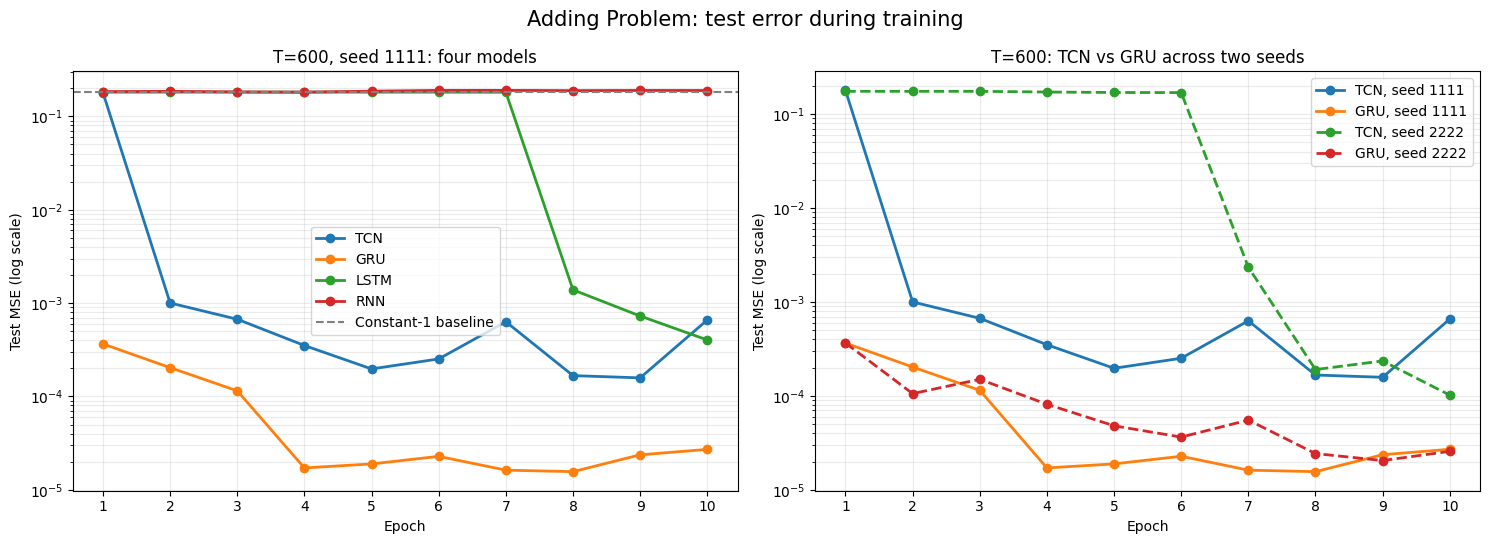

그래프: /content/TCN/reproduction_logs/adding_T600_10epoch_comparison_20261124.png
수치표: /content/TCN/reproduction_logs/adding_T600_10epoch_results_20261124.csv
다운로드 ZIP: /content/TCN/reproduction_logs/adding_T600_10epoch_presentation_files_20261124.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import csv
import re
import zipfile
from pathlib import Path
import matplotlib.pyplot as plt

def read_tcn_mse(log_path):
    text = Path(log_path).read_text(encoding="utf-8")
    values = re.findall(r"Test set: Average loss:\s*([0-9.]+)", text)
    if len(values) != 10:
        raise ValueError(f"TCN 로그에서 10개 값을 찾지 못했습니다: {log_path}")
    return [float(value) for value in values]

tcn1111 = read_tcn_mse(tcn1111_10epoch_log)
tcn2222 = read_tcn_mse(tcn_10epoch_log)

series = {
    (1111, "TCN"): tcn1111,
    (1111, "GRU"): [mse for _, mse in gru600_results],
    (1111, "LSTM"): [mse for _, mse in lstm600_results],
    (1111, "RNN"): [mse for _, mse in rnn600_results],
    (2222, "TCN"): tcn2222,
    (2222, "GRU"): [mse for _, mse in gru2222_results],
}

for key, values in series.items():
    if len(values) != 10:
        raise ValueError(f"{key}의 에폭 결과가 10개가 아닙니다.")

output_dir = Path("/content/TCN/reproduction_logs")
png_path = output_dir / "adding_T600_10epoch_comparison_20261124.png"
csv_path = output_dir / "adding_T600_10epoch_results_20261124.csv"
zip_path = output_dir / "adding_T600_10epoch_presentation_files_20261124.zip"

with csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["seed", "model", "epoch", "test_mse"])
    for (seed, model), values in series.items():
        for epoch, mse in enumerate(values, start=1):
            writer.writerow([seed, model, epoch, mse])

epochs = range(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for model in ("TCN", "GRU", "LSTM", "RNN"):
    axes[0].plot(
        epochs, series[(1111, model)],
        marker="o", linewidth=2, label=model
    )
axes[0].axhline(
    constant_one_mse,
    color="gray", linestyle="--", label="Constant-1 baseline"
)
axes[0].set_title("T=600, seed 1111: four models")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Test MSE (log scale)")
axes[0].set_yscale("log")
axes[0].set_xticks(list(epochs))
axes[0].grid(True, which="both", alpha=0.25)
axes[0].legend()

for seed, model, style in (
    (1111, "TCN", "-"),
    (1111, "GRU", "-"),
    (2222, "TCN", "--"),
    (2222, "GRU", "--"),
):
    axes[1].plot(
        epochs, series[(seed, model)],
        style, marker="o", linewidth=2,
        label=f"{model}, seed {seed}"
    )
axes[1].set_title("T=600: TCN vs GRU across two seeds")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test MSE (log scale)")
axes[1].set_yscale("log")
axes[1].set_xticks(list(epochs))
axes[1].grid(True, which="both", alpha=0.25)
axes[1].legend()

fig.suptitle("Adding Problem: test error during training", fontsize=15)
fig.tight_layout()
fig.savefig(png_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    archive.write(png_path, png_path.name)
    archive.write(csv_path, csv_path.name)

print("그래프:", png_path)
print("수치표:", csv_path)
print("다운로드 ZIP:", zip_path)

from google.colab import files
files.download(str(zip_path))